In [4]:
from ultralytics import YOLO
import cv2
import numpy as np
import os
from llm_tools import UseLLM
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
%matplotlib

Using matplotlib backend: module://matplotlib_inline.backend_inline


In [5]:
api_key = os.getenv("API_KEY")
chatgpt = UseLLM(api_key=api_key)

In [6]:
image_path ='./datasets/new_wastes/test/images/317376fc47dafdee5d71de5ee8c9a083_mp4-0003_jpg.rf.04425e56a6e604dd69c9fa24451cb976.jpg' 
classnames = ['bottle', 'carton', 'dixie_cup', 'paper']

# Define a fixed color map for classes
common_colors = [
    (255, 0, 0),    # Red
    (0, 255, 0),    # Green
    (0, 0, 255),    # Blue
    (255, 255, 0),  # Yellow
    (255, 0, 255),  # Magenta
    (0, 255, 255),  # Cyan
    (128, 0, 0),    # Maroon
    (0, 128, 0),    # Dark green
    (0, 0, 128),    # Navy
    (128, 128, 0)   # Olive
]

# Limit the number of colors to the number of classes
# Limit the number of colors to match the number of categories.
num_classes = 4
colors = {i: common_colors[i % len(common_colors)] for i in range(num_classes)}


# Count detections per class
class_counts = {}

In [16]:
# Load a model
model = YOLO("yolo11n-seg.pt")  # load an official model
model = YOLO("./runs/segment/train3/weights/best.pt")  # load a custom model


In [8]:
model

YOLO(
  (model): SegmentationModel(
    (model): Sequential(
      (0): Conv(
        (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (1): Conv(
        (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (2): C3k2(
        (cv1): Conv(
          (conv): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
          (act): SiLU(inplace=True)
        )
        (cv2): Conv(
          (conv): Conv2d(96, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(128, eps=0.001, momentum=0.03, affine=True, track_run

In [9]:
# Read the image
# Read the image.
image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Convert to RGB for the YOLO model

# Run model prediction
print(image.shape)
results = model(image_path)

(640, 640, 3)

image 1/1 ./datasets/new_wastes/test/images/317376fc47dafdee5d71de5ee8c9a083_mp4-0003_jpg.rf.04425e56a6e604dd69c9fa24451cb976.jpg: 640x640 3 bottles, 1 dixie_cup, 3 papers, 286.1ms
Speed: 2.9ms preprocess, 286.1ms inference, 9.2ms postprocess per image at shape (1, 3, 640, 640)


In [10]:
results

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 keypoints: None
 masks: ultralytics.engine.results.Masks object
 names: {0: 'bottle', 1: 'carton', 2: 'dixie_cup', 3: 'paper'}
 obb: None
 orig_img: array([[[34, 32, 38],
         [34, 32, 38],
         [34, 32, 38],
         ...,
         [54, 61, 58],
         [52, 59, 56],
         [51, 58, 55]],
 
        [[36, 34, 40],
         [36, 34, 40],
         [37, 35, 41],
         ...,
         [53, 60, 57],
         [51, 58, 55],
         [51, 58, 55]],
 
        [[36, 34, 40],
         [37, 35, 41],
         [37, 35, 41],
         ...,
         [52, 59, 56],
         [51, 58, 55],
         [50, 57, 54]],
 
        ...,
 
        [[38, 43, 41],
         [39, 44, 42],
         [40, 45, 43],
         ...,
         [62, 67, 66],
         [62, 67, 66],
         [62, 67, 66]],
 
        [[42, 47, 45],
         [42, 47, 45],
         [43, 48, 46],
         ...,
         [65, 70, 69],


In [11]:
# Visualize segmentation results
for result in results:
    masks = result.masks.data.cpu().numpy()  # Masks shaped (num_objects, height, width)
    classes = result.boxes.cls.cpu().numpy()  # Class index per object
    scores = result.boxes.conf.cpu().numpy()  # Confidence per object
    
    for i, mask in enumerate(masks):
        # Class color
        class_idx = int(classes[i])
        mask_color = colors[class_idx]

        # Update class counts
        class_counts[class_idx] = class_counts.get(class_idx, 0) + 1



        # Colorize the mask
        mask = (mask > 0.5).astype(np.uint8)  # Binarize the mask
        mask_colored = np.stack([mask * mask_color[0], mask * mask_color[1], mask * mask_color[2]], axis=-1)
        
        # Overlay the mask on the image
        image = cv2.addWeighted(image, 1.0, mask_colored, 0.5, 0)

        # Draw class name and score
        # bbox = result.boxes.xyxy[i].cpu().numpy().astype(int)  # Bounding box (xmin, ymin, xmax, ymax)
        label = f"{int(classes[i])} {scores[i]:.2f}"
        print(label)

3 0.93
0 0.93
0 0.92
0 0.92
2 0.84
3 0.72
3 0.46


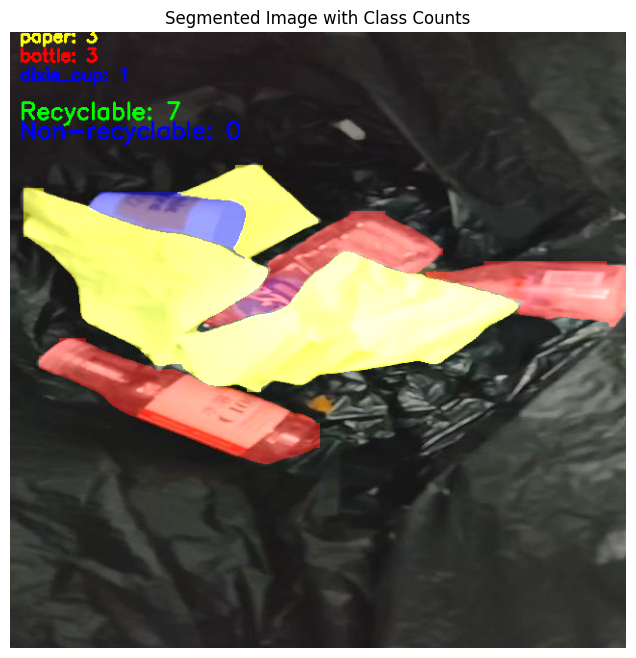

In [12]:
# Draw class counts in the top-left
line_height = 20  # Line height
start_x, start_y = 10, 10  # Start position
recyclables_count = 0
unrecyclable_count = 0
report_input = []
for class_idx, count in class_counts.items():
    message = f'{classnames[class_idx]}Is it recyclable waste? If yes, return True; if no, return False.'
    result = chatgpt.use(message=message)
    if result:
        recyclables_count +=count
    else:
        unrecyclable_count += count
    text = f"{classnames[class_idx]}: {count}"
    report_input.append(text)
    color = colors[class_idx]
    cv2.putText(image, text, (start_x, start_y), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
    start_y += line_height

cv2.putText(image, f"Recyclable: {recyclables_count}", (start_x, start_y+line_height),
            cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
cv2.putText(image, f"Non-recyclable: {unrecyclable_count}", (start_x, start_y + 2*line_height),
            cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2)
# # Convert to BGR for OpenCV display
# image = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)

# # Show the result
# cv2.imshow("Segmented Image", image)
# cv2.waitKey(0)
# cv2.destroyAllWindows()

# # Save the result if needed
# cv2.imwrite("segmented_output.jpg", image)


# Display in the notebook output
clear_output(wait=True)  # Clear previous output
plt.figure(figsize=(10, 8))
plt.imshow(image)
plt.axis('off')
plt.title("Segmented Image with Class Counts")
display(plt.gcf())  # Show the current figure




In [13]:
report_input

['paper: 3', 'bottle: 3', 'dixie_cup: 1']

In [14]:
report_message = ','.join(report_input) + 'Please generate a report based on the above waste, including waste disposal methods in the content.'
text = chatgpt.use(report_message)
print(text)

### Waste Disposal Report

#### Overview of Waste Collected
The waste collected consists of the following items:
- **Paper**: 3 units
- **Bottle**: 3 units
- **Dixie Cup**: 1 unit

#### Waste Composition Analysis
1. **Paper (3 units)**: This includes items such as newspapers, office paper, or packaging materials. Paper is a recyclable material that can be processed to create new paper products, reducing the need for virgin materials and conserving natural resources.

2. **Bottle (3 units)**: This likely refers to plastic or glass bottles. Bottles are significant contributors to waste but can be recycled effectively. Recycling bottles helps to reduce pollution, conserve energy, and decrease landfill waste.

3. **Dixie Cup (1 unit)**: Dixie cups are typically made from paper or plastic. If they are made from paper, they may be recyclable, but if they are coated with plastic for waterproofing, they may not be accepted in standard recycling programs.

#### Recommended Waste Disposal Method